# Etapa 3: árvore de decisão

Entrada: as linhas completas de `data/processed/chembl_4targets.csv` (`eda.complete_rows`), geradas pela etapa 1 e analisadas na etapa 2.

A etapa responde a duas perguntas que a análise exploratória deixou em aberto:

1. **A coluna `SMILES` ajuda?** Até aqui ela foi descartada. Cada descritor isolado acerta no máximo 45%.
2. **Quanto do resultado é vazamento?** 4.777 linhas repetem exatamente os 5 descritores de outra linha. Num split aleatório, cópias caem dos dois lados.

O código fica em `src/modeling.py`; os gráficos, em `src/plots.py`.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from src import modeling, plots
from src.config import FINAL_CSV

plots.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

final = pd.read_csv(FINAL_CSV)
dados = modeling.prepare(final)
print("X:", dados.X.shape, "| classes:", dados.y.nunique())
dados.X.head()

X: (27476, 17) | classes: 4


,Molecular Weight,LogP,HBA,HBD,TPSA,smiles_len,n_N,n_O,n_S,n_halogen,n_rings,n_branch,n_aromatic,n_double,n_triple,n_charge,n_stereo
0,236.37,3.37,4.0,0.0,17.82,26,2,0,2,0,3,2,10,0,0,1,0
1,328.44,2.62,6.0,2.0,51.10,36,4,1,1,0,4,2,11,1,0,0,0
2,421.59,4.42,4.0,0.0,36.02,48,3,2,0,0,4,4,12,1,0,0,0
3,346.82,5.01,4.0,1.0,50.70,38,4,0,0,1,4,2,22,0,0,0,0
4,243.31,2.56,3.0,2.0,41.49,22,1,2,0,0,2,0,12,0,0,0,0


`prepare` monta de uma vez a matriz de features, o rótulo, os ids de grupo e os dois splits. A matriz traz as 17 colunas candidatas: os 5 descritores e as 12 contagens de caracteres do SMILES. O `pChEMBL` fica de fora — é o resultado do ensaio contra o alvo, então só existe depois que o alvo é conhecido.

## 1. Features derivadas do SMILES

O SMILES é a estrutura da molécula escrita como texto: `Cc1ccc(N2CCN(C)CC2)cc1`. Transformar isso em features costuma exigir uma biblioteca de química, que o projeto não usa. A alternativa é tratar o SMILES como string e **contar caracteres**: tamanho, nitrogênios, oxigênios, halogênios, anéis, ramificações, átomos aromáticos, ligações duplas e triplas, cargas e marcas de estereoquímica.

São 12 colunas inteiras, cada uma com significado direto, então a árvore continua legível. Dois detalhes de implementação importam: `Cl` e `Br` viram um símbolo único antes da contagem, senão o `C` de `Cl` entra na conta de carbono; e letras minúsculas contam junto com maiúsculas, porque a minúscula só marca que o átomo está num anel aromático.

In [2]:
modeling.feature_summary(dados)

,mean,std,min,50%,max
smiles_len,58.8,16.2,14.0,57.0,220.0
n_N,4.6,1.9,0.0,4.0,18.0
n_O,2.6,1.7,0.0,2.0,17.0
n_S,0.4,0.6,0.0,0.0,6.0
n_halogen,1.2,1.4,0.0,1.0,12.0
n_rings,4.1,1.1,0.0,4.0,12.0
n_branch,5.5,2.7,0.0,5.0,23.0
n_aromatic,15.8,5.2,0.0,16.0,52.0
n_double,1.8,1.3,0.0,2.0,11.0
n_triple,0.1,0.4,0.0,0.0,3.0


## 2. Descritores repetidos vazam entre treino e teste

A etapa 2 encontrou 4.777 linhas que repetem exatamente os 5 descritores de outra linha — isômeros e análogos da mesma série química. Num split aleatório, nada impede que uma linha e sua cópia caiam em lados opostos.

In [3]:
modeling.group_leakage(dados)

,valor
linhas completas,27476.0
tuplas de descritores distintas,22699.0
linhas que repetem outra,4777.0
maior grupo,12.0
grupos com mais de uma classe,0.0
teste com gêmeo no treino (split aleatório),1397.0
% do teste com gêmeo,25.4


Duas linhas dessa tabela explicam o problema:

- **Nenhum grupo tem mais de uma classe.** Linhas com descritores idênticos sempre pertencem ao mesmo alvo.
- **25,4% do teste teria um gêmeo no treino.** Como o gêmeo tem os mesmos valores e a mesma classe, a árvore não precisa generalizar: basta decorar. Um quarto do conjunto de teste vira gabarito.

A correção é agrupar: linhas com a mesma tupla de descritores nunca se separam entre treino e teste. O id de grupo sai de `pd.factorize` sobre a tupla convertida em texto, o que evita comparar `float` por igualdade.

## 3. Os dois splits

Os dois são calculados e reportados. O **aleatório** (`train_test_split` estratificado) é o número que qualquer trabalho de ML reporta. O **agrupado** (primeiro fold de `StratifiedGroupKFold`) é o número honesto. A diferença entre eles é um resultado desta etapa.

In [4]:
modeling.split_summary(dados)

aleatória                        agrupada               
        treino (n=21980) teste (n=5496) treino (n=21980) teste (n=5496)
Protein                                                                
EGFR                29.3           29.3             29.3           29.3
BACE1               26.6           26.6             26.6           26.6
DRD2                23.8           23.8             23.8           23.8
HDAC1               20.3           20.3             20.3           20.3

Os dois splits têm o mesmo tamanho (21.980 treino, 5.496 teste) e mantêm as proporções das classes, então a comparação entre eles isola exatamente o efeito do agrupamento.

## 4. Busca de hiperparâmetros

`GridSearchCV` sobre 72 combinações: `criterion` (gini, entropy), `max_depth` (8, 12, 16, sem limite), `min_samples_leaf` (1, 5, 20) e `ccp_alpha` (0, 1e-4, 3e-4). Com 5 partes de validação cruzada, são 361 árvores por cenário.

A métrica é acurácia. As classes vão de 20,3% a 29,3%, perto o bastante do equilíbrio para que acurácia e F1 macro ordenem os candidatos igual, e a acurácia mantém a comparação direta com o piso de 29,3% da etapa 2.

Um detalhe mais importante do que parece: **a validação cruzada interna precisa respeitar o mesmo agrupamento do split externo**. Usar `StratifiedKFold` dentro de um treino agrupado produz uma estimativa cerca de 5 pontos otimista — o vazamento volta por dentro do tuning, mesmo com a divisão externa correta. Por isso `tune_all` escolhe o splitter a partir do nome do split, em vez de deixar isso na mão de quem chama.

Os 6 cenários são 3 conjuntos de features × 2 splits. Leva cerca de 50 segundos.

In [5]:
comparacao, modelos = modeling.tune_all(dados)
comparacao

,features,split,acurácia CV,acurácia teste,F1 macro teste,folhas,profundidade,ccp_alpha
0,descritores,aleatória,0.794,0.807,0.806,3330,25,0.0001
1,descritores,agrupada,0.754,0.771,0.770,1124,20,0.0003
2,descritores + SMILES,aleatória,0.896,0.907,0.906,1849,24,0.0000
3,descritores + SMILES,agrupada,0.878,0.897,0.896,1854,24,0.0000
4,só SMILES,aleatória,0.882,0.892,0.889,2818,26,0.0000
5,só SMILES,agrupada,0.865,0.876,0.873,2758,24,0.0000


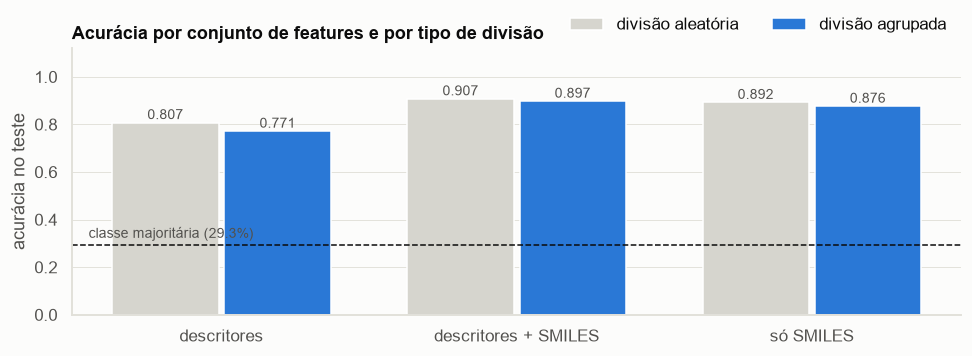

In [6]:
plots.model_comparison(comparacao, baseline=0.293)

O resultado principal: **as contagens de caracteres do SMILES valem cerca de 10 pontos de acurácia**, em qualquer um dos splits. Mais surpreendente, as 12 contagens sozinhas (0,876) batem os 5 descritores físico-químicos (0,771) por 10 pontos. Massa, LogP, HBA, HBD e TPSA resumem a molécula em cinco números; contar os caracteres do SMILES preserva pistas de tamanho, composição e topologia que esse resumo joga fora.

Todos os cenários ficam muito acima do piso de 29,3%, então o sinal é real.

In [7]:
modeling.best_params_table(modelos)

,features,split,ccp_alpha,criterion,max_depth,min_samples_leaf
0,descritores,aleatória,0.0001,entropy,None,1
1,descritores,agrupada,0.0003,entropy,None,1
2,descritores + SMILES,aleatória,0.0000,entropy,None,1
3,descritores + SMILES,agrupada,0.0000,entropy,None,1
4,só SMILES,aleatória,0.0000,entropy,None,1
5,só SMILES,agrupada,0.0000,entropy,None,1


O tuning escolhe `entropy` e nenhum limite de profundidade nos 6 cenários, e só liga a poda (`ccp_alpha` > 0) quando as features são apenas os descritores. Faz sentido: com 22 mil linhas de treino, o critério de parada da própria árvore já fica perto do ideal, e `min_samples_leaf` acima de 1 nunca vence. Vale registrar como resultado negativo — o tuning confirma o padrão em vez de melhorá-lo.

## 5. Quanto o split aleatório superestima

In [8]:
modeling.leakage_gap(comparacao)

split,agrupada,aleatória,diferença (pontos)
features,,,
descritores,0.771,0.807,3.6
descritores + SMILES,0.897,0.907,1.0
só SMILES,0.876,0.892,1.6


O vazamento infla **3,6 pontos** com os descritores puros e só **1 ponto** com as features de SMILES. A razão é que o agrupamento é definido pelos descritores: moléculas com descritores idênticos têm SMILES diferentes, então as contagens de caracteres não são copiadas junto. O atalho de decorar vale menos quando o modelo tem sinal de verdade.

**Limitação a declarar.** O agrupamento cobre descritores idênticos, não séries químicas inteiras. Análogos do mesmo artigo continuam espalhados entre treino e teste, e as features de SMILES permitem decorar famílias estruturais. Controlar isso exigiria dividir por esqueleto molecular, o que precisa de uma biblioteca de química. Então 0,897 ainda é otimista para moléculas realmente novas.

Das seções 6 em diante, tudo usa o cenário honesto: todas as features, split agrupado.

## 6. Profundidade e overfitting

A curva varre `max_depth` de 2 a 25 medindo acurácia de treino e de validação cruzada na mesma varredura.

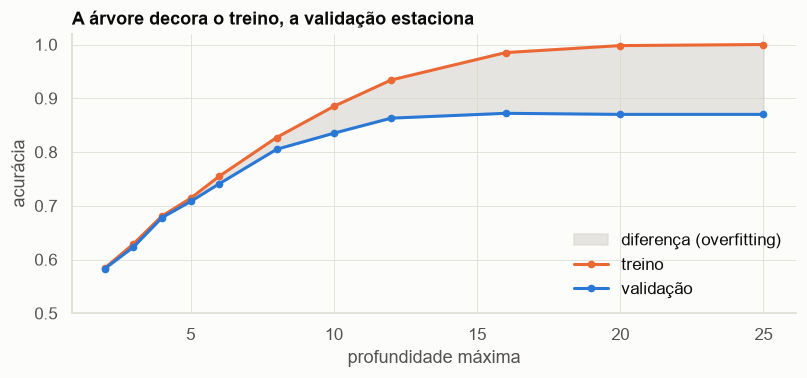

In [9]:
plots.depth_curve(modeling.depth_curve(dados))

O overfitting é visível: o treino chega a 100% na profundidade 25, enquanto a validação estaciona em torno de 0,87 a partir da profundidade 16. A área cinza entre as curvas é o que a árvore decorou sem conseguir generalizar. Até a profundidade 12 as duas curvas sobem juntas — é aí que está o aprendizado real.

## 7. Poda por custo-complexidade

`ccp_alpha` penaliza folhas: quanto maior, menor a árvore. É a forma de poda que a própria árvore calcula, em vez de cortar numa profundidade fixa.

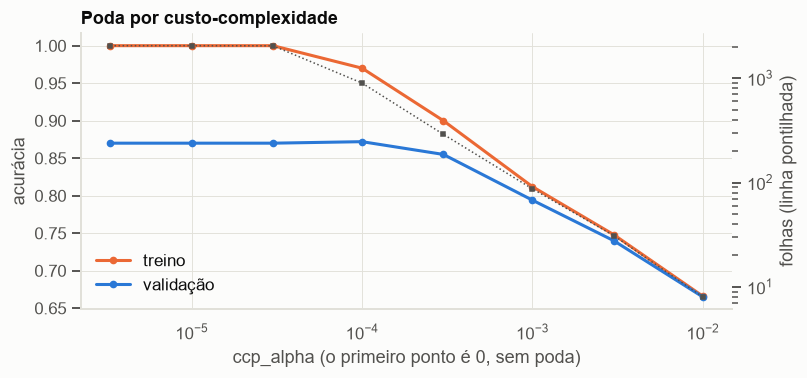

In [10]:
plots.pruning_curve(modeling.pruning_curve(dados))

Em `ccp_alpha = 1e-4` a árvore cai de 2.054 para 899 folhas e a validação não piora — melhora de 0,870 para 0,872. Menos da metade do tamanho pelo mesmo desempenho. A partir de 1e-3 a poda passa a custar acurácia, e em 1e-2 sobram 8 folhas e 0,665.

## 8. O que a árvore aprendeu

A árvore escolhida tem 1.854 folhas e 24 níveis: desenhá-la inteira não produz nada legível. As primeiras camadas, porém, mostram as perguntas que mais separam as classes.

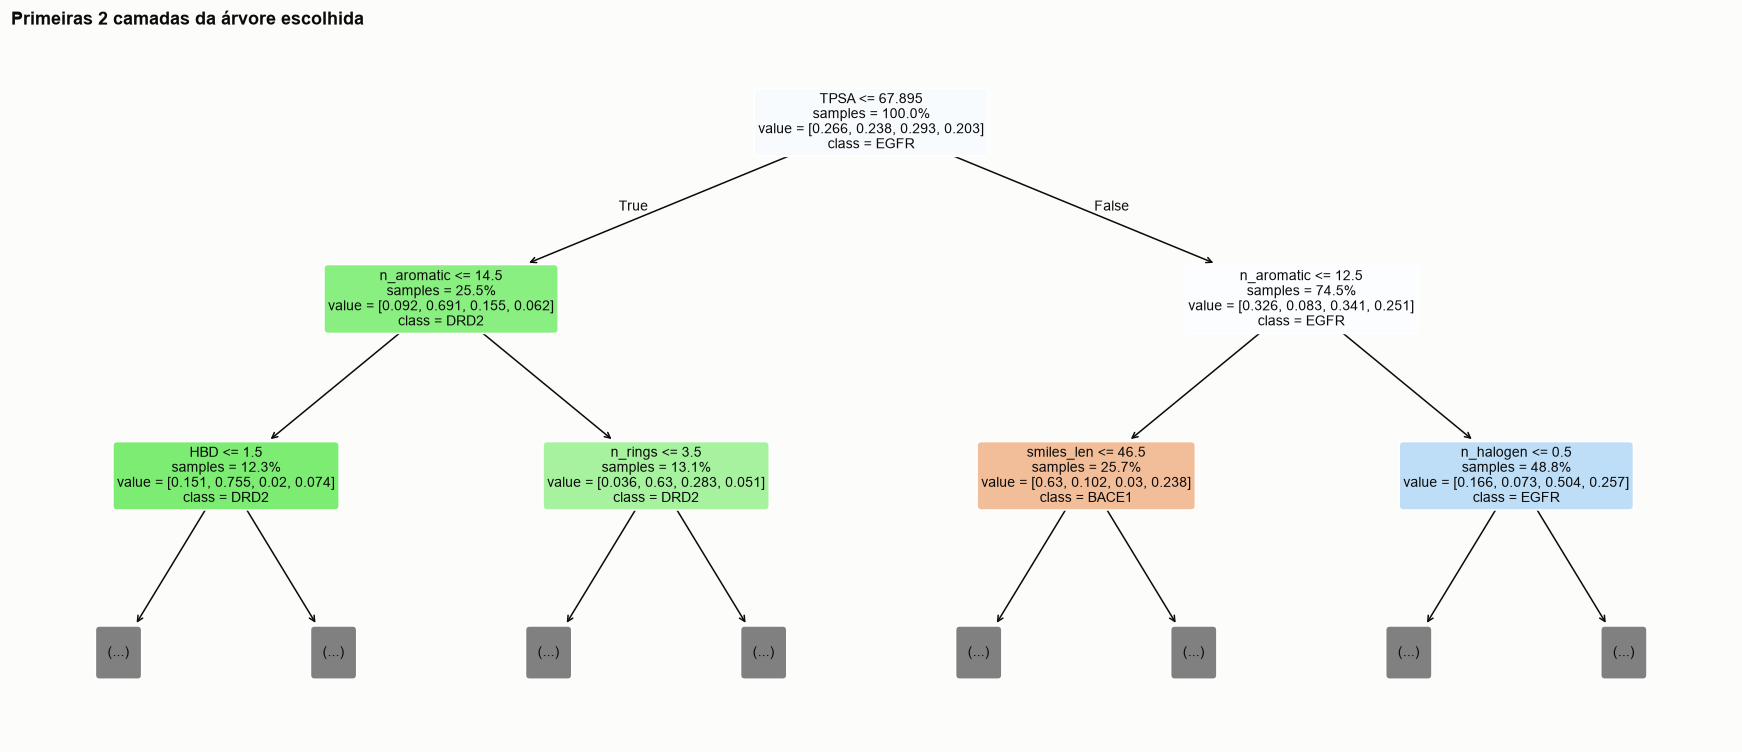

In [11]:
arvore = modelos[modeling.CHOSEN]
plots.decision_tree(arvore, dados)

In [12]:
print(modeling.tree_rules(arvore, dados))

|--- TPSA <= 67.90
|   |--- n_aromatic <= 14.50
|   |   |--- HBD <= 1.50
|   |   |   |--- truncated branch of depth 14
|   |   |--- HBD >  1.50
|   |   |   |--- truncated branch of depth 12
|   |--- n_aromatic >  14.50
|   |   |--- n_rings <= 3.50
|   |   |   |--- truncated branch of depth 9
|   |   |--- n_rings >  3.50
|   |   |   |--- truncated branch of depth 15
|--- TPSA >  67.90
|   |--- n_aromatic <= 12.50
|   |   |--- smiles_len <= 46.50
|   |   |   |--- truncated branch of depth 16
|   |   |--- smiles_len >  46.50
|   |   |   |--- truncated branch of depth 15
|   |--- n_aromatic >  12.50
|   |   |--- n_halogen <= 0.50
|   |   |   |--- truncated branch of depth 22
|   |   |--- n_halogen >  0.50
|   |   |   |--- truncated branch of depth 18



O primeiro corte é sempre `TPSA`, em 67,90 — coerente com a etapa 2, onde DRD2 se destacava por TPSA baixa. Logo em seguida vem `n_aromatic`, uma das contagens de SMILES, e depois `HBD`, `n_rings` e `smiles_len`. As duas representações se misturam já no topo da árvore, em vez de uma dominar a outra.

## 9. Importância das features

Duas medidas, porque elas discordam. A **impureza** conta quanto cada feature reduziu a impureza durante o treino, e divide o crédito entre features correlacionadas: a etapa 2 mostrou que `TPSA`, `HBA` e `HBD` medem todas polaridade. A **permutação** embaralha uma coluna no conjunto de teste e mede quanto o desempenho cai — mede utilidade, não uso.

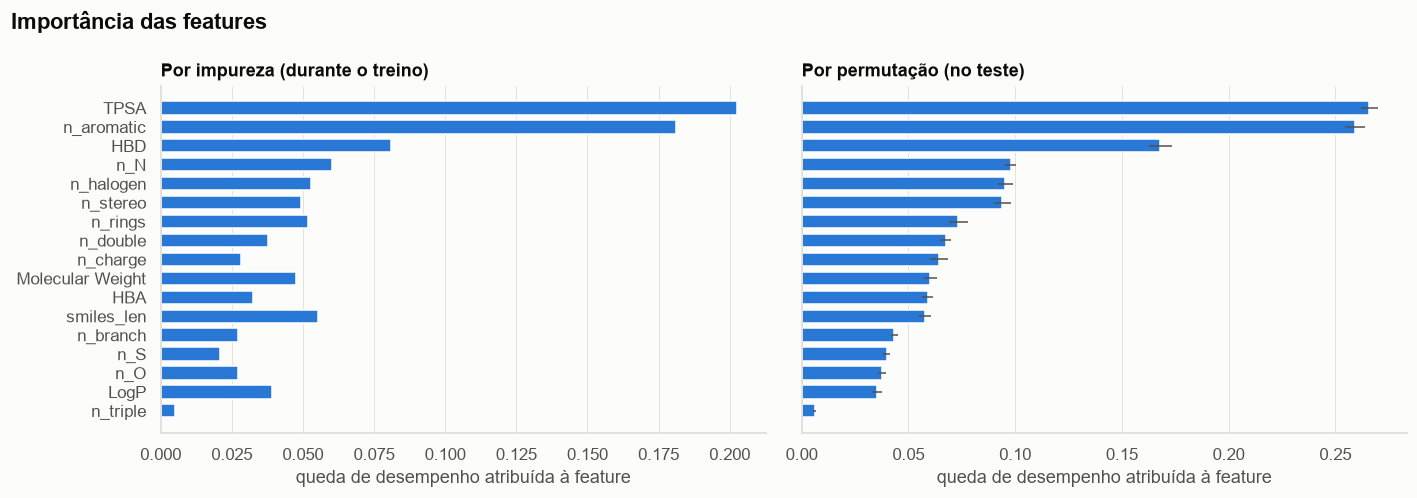

In [13]:
plots.feature_importances(modeling.importances(arvore, dados))

`TPSA` e `n_aromatic` lideram nas duas medidas, com folga. Depois delas vem `HBD`, e a seguir um bloco de contagens de SMILES (`n_N`, `n_halogen`, `n_stereo`, `n_rings`) acima de descritores clássicos como `LogP` e `HBA`. As duas colunas da figura concordam na ordem geral, mas a permutação dá mais peso às contagens — sinal de que elas carregam informação que as outras features não substituem.

## 10. Avaliação no conjunto de teste

In [14]:
relatorio, matriz = modeling.evaluation(arvore, dados)
relatorio

,precisão,revocação,F1,linhas
EGFR,0.877,0.899,0.888,1612.000
BACE1,0.910,0.913,0.911,1463.000
DRD2,0.930,0.901,0.916,1307.000
HDAC1,0.869,0.867,0.868,1114.000
accuracy,0.897,0.897,0.897,0.897
macro avg,0.897,0.895,0.896,5496.000


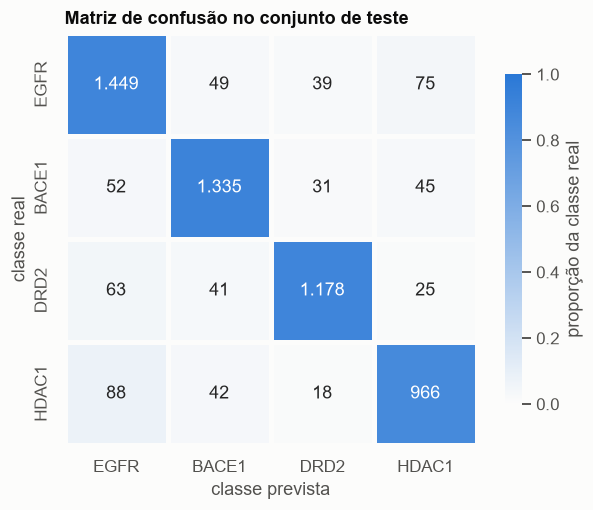

In [15]:
plots.confusion_matrix(matriz)

Acurácia de 0,897 e F1 macro de 0,896: nenhuma classe foi sacrificada. DRD2 é a mais fácil (F1 0,916), coerente com a etapa 2, que a mostrou isolada na região de TPSA baixa. HDAC1 é a mais difícil (F1 0,868), e a maior confusão é justamente entre HDAC1 e EGFR, nos dois sentidos — as duas classes que mais se sobrepunham nos gráficos da etapa 2.

## 11. Piso e teto

A árvore sozinha fica entre dois pontos de referência: chutar a classe majoritária e um conjunto de centenas de árvores.

In [16]:
modeling.reference_models(dados)

,acurácia teste,F1 macro teste
modelo,,
Dummy (classe majoritária),0.293,0.113
Random Forest (300 árvores),0.952,0.952
HistGradientBoosting,0.947,0.946


O piso é 0,293 e o teto, 0,952. A árvore única entrega 0,897: captura a maior parte do que há para aprender, e paga cerca de 5 pontos pela simplicidade. Os 5 pontos são o preço da interpretabilidade — a floresta acerta mais, mas não há como ler suas regras, enquanto a árvore responde "por que esta molécula foi classificada como DRD2" com um caminho de perguntas.

## 12. Resumo

| Conjunto de features | Split aleatório | Split agrupado |
|---|---|---|
| 5 descritores | 0,807 | 0,771 |
| só SMILES (12 contagens) | 0,892 | 0,876 |
| descritores + SMILES | 0,907 | **0,897** |

- **A coluna `SMILES` ajuda muito.** Contar caracteres rende cerca de 10 pontos de acurácia, e as contagens sozinhas superam os 5 descritores físico-químicos.
- **O split aleatório superestima.** 3,6 pontos com os descritores, 1 ponto quando há mais sinal. 25,4% do teste teria um gêmeo de descritores no treino.
- **O tuning muda pouco.** Com 22 mil linhas, a árvore sem limite de profundidade já está perto do ideal; a poda em `ccp_alpha = 1e-4` corta mais da metade das folhas sem perder acurácia.
- **Limite do método.** O agrupamento cobre descritores idênticos, não séries químicas. Dividir por esqueleto molecular exigiria uma biblioteca de química, fora do escopo do projeto.
- **A base só tem moléculas ativas.** O modelo separa alvos entre si; não diz se uma molécula é ativa ou inativa.

Resultado final: **0,897 de acurácia e 0,896 de F1 macro** com split agrupado, contra 0,293 de piso e 0,952 de uma floresta aleatória.